# ITC 3154 – Cognitive Computing | Assignment 1 (Fall 2026)
**Exploratory Data Analysis of the Loan Approval dataset**

Student: Pantelis Donoupoglou
Instructor: Dr. Dimitris Grigoriadis

Goal: explore the dataset with pandas / NumPy / SciPy / matplotlib / seaborn and identify which features matter for predicting `loan_status` (Approved vs Rejected).

## 0. Setup – libraries and plotting style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', palette='Set2')
SAVE_FIGS = True   # saves every plot as PNG in ./figures (used in the report)
import os; os.makedirs('figures', exist_ok=True)

## Task 1 & 2 – Load the dataset and print the first 20 rows
The Blackboard file is **semicolon-separated** and every text value / column name starts with a space
(e.g. `" Approved"`). `skipinitialspace=True` plus `.str.strip()` cleans this up – otherwise
`df['loan_status'] == 'Approved'` would silently return no rows.

In [2]:
df = pd.read_csv('loan_approval_dataset.csv', sep=';', skipinitialspace=True)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].str.strip()

print('Shape:', df.shape)
df.head(20)

Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


### First look at structure, types and quality

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Duplicate loan_id:', df['loan_id'].duplicated().sum())

Missing values per column:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate rows: 0
Duplicate loan_id: 0


In [5]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
loan_id,4269.0,2135.0,1232.5,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,2.5,1.7,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5059123.9,2806839.8,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,15133450.5,9043363.0,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,10.9,5.7,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,599.9,172.4,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7472616.5,6503636.6,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4973155.3,4388966.1,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,15126305.9,9103753.7,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4976692.4,3250185.3,0.0,2300000.0,4600000.0,7100000.0,14700000.0


In [6]:
# Categorical columns
for col in ['education', 'self_employed', 'loan_status']:
    print(df[col].value_counts(), '\n')

education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64 

self_employed
Yes    2150
No     2119
Name: count, dtype: int64 

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64 



In [7]:
# Data-quality check: asset values should never be negative
neg = (df[['residential_assets_value','commercial_assets_value',
           'luxury_assets_value','bank_asset_value']] < 0).sum()
print(neg)
print(df.loc[df['residential_assets_value'] < 0, 'residential_assets_value'].unique())

residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64
[-100000]


**Observations:** 4,269 applications, 13 columns, no missing values and no duplicates.
`loan_id` is only an identifier. 28 rows have a negative `residential_assets_value` (-100,000), which is
impossible in reality – most likely a data-entry placeholder. Because they are only 0.7 % of the data they are
kept for the EDA, but they would be cleaned (e.g. set to 0 / median) before modelling.

### Target variable balance

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64 

loan_status
Approved    62.2
Rejected    37.8
Name: count, dtype: float64


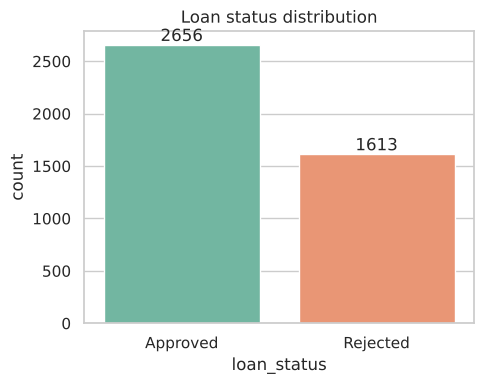

In [8]:
counts = df['loan_status'].value_counts()
print(counts, '\n')
print((counts / len(df) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='loan_status', hue='loan_status', ax=ax, legend=False)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Loan status distribution')
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/01_target_balance.png', dpi=150)
plt.show()

62.2 % Approved vs 37.8 % Rejected – moderately imbalanced, not severe.

### Distribution of the numeric features

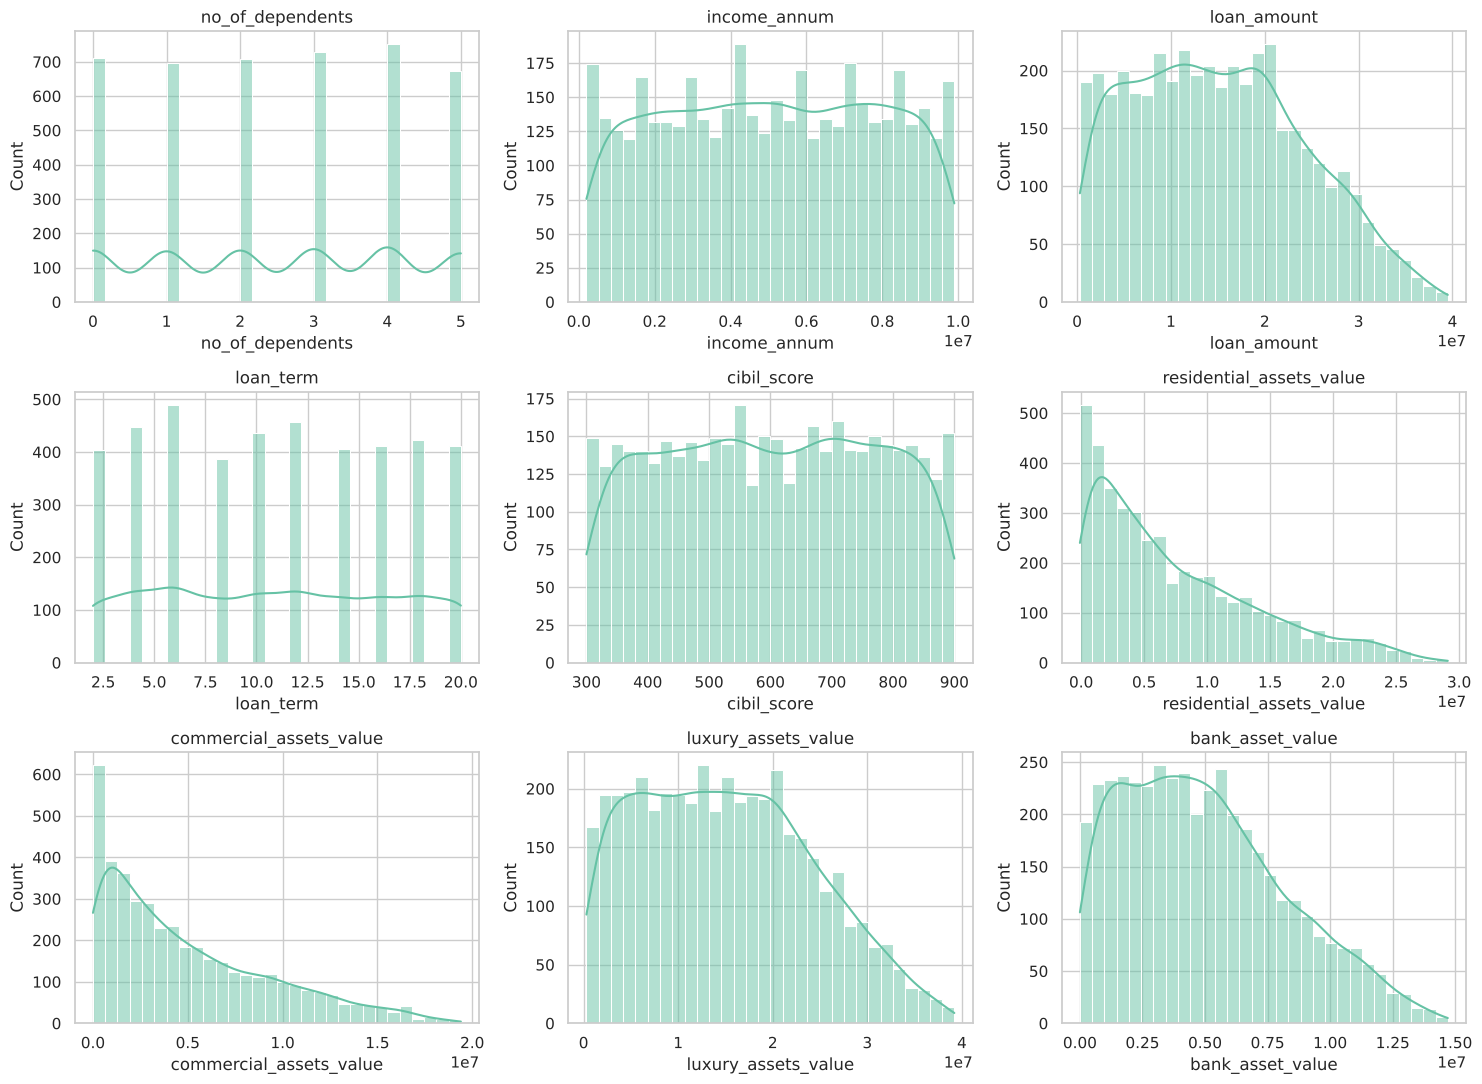

Skewness:
no_of_dependents           -0.02
income_annum               -0.01
loan_amount                 0.31
loan_term                   0.04
cibil_score                -0.01
residential_assets_value    0.98
commercial_assets_value     0.96
luxury_assets_value         0.32
bank_asset_value            0.56
dtype: float64


In [9]:
num_cols = ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
            'residential_assets_value', 'commercial_assets_value',
            'luxury_assets_value', 'bank_asset_value']

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/02_histograms.png', dpi=150)
plt.show()

print('Skewness:')
print(df[num_cols].skew().round(2))

## Task 3 – Which features matter for `loan_status`?
The importance table is filled **manually** in the report (domain reasoning). The cells below provide the evidence
behind it: approval rate per category and mean of each numeric feature by outcome.

In [10]:
df.groupby('loan_status')[num_cols].mean().T.round(0)

loan_status,Approved,Rejected
no_of_dependents,2.0,3.0
income_annum,5025904.0,5113825.0
loan_amount,15247252.0,14946063.0
loan_term,10.0,12.0
cibil_score,703.0,429.0
residential_assets_value,7399812.0,7592498.0
commercial_assets_value,5001355.0,4926720.0
luxury_assets_value,15016604.0,15306944.0
bank_asset_value,4959526.0,5004960.0


In [11]:
# Approval rate per category of the low-cardinality features
for col in ['education', 'self_employed', 'no_of_dependents', 'loan_term']:
    rate = pd.crosstab(df[col], df['loan_status'], normalize='index').round(3) * 100
    print(f'--- {col} (% of applicants) ---')
    print(rate, '\n')

--- education (% of applicants) ---
loan_status   Approved  Rejected
education                       
Graduate          62.5      37.5
Not Graduate      62.0      38.0 

--- self_employed (% of applicants) ---
loan_status    Approved  Rejected
self_employed                    
No                 62.2      37.8
Yes                62.2      37.8 

--- no_of_dependents (% of applicants) ---
loan_status       Approved  Rejected
no_of_dependents                    
0                     64.2      35.8
1                     61.7      38.3
2                     62.3      37.7
3                     62.9      37.1
4                     61.8      38.2
5                     60.3      39.7 

--- loan_term (% of applicants) ---
loan_status  Approved  Rejected
loan_term                      
2                78.0      22.0
4                81.9      18.1
6                57.6      42.4
8                57.0      43.0
10               52.5      47.5
12               60.5      39.5
14               59

## Task 4 – Correlation heat map
`loan_status` is converted to a number (Approved = 1, Rejected = 0) so that its correlation with
every numeric feature appears in the matrix. Text columns are excluded because `.corr()` only works on numbers.

In [12]:
df['loan_status_num'] = (df['loan_status'] == 'Approved').astype(int)

numeric_df = df.drop(columns=['loan_id']).select_dtypes(include=np.number)
corrmatrix = numeric_df.corr()          # Pearson correlation (pandas .corr())
corrmatrix.round(2)

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status_num
no_of_dependents,1.00,0.01,-0.00,-0.02,-0.01,0.01,-0.00,0.00,0.01,-0.02
income_annum,0.01,1.00,0.93,0.01,-0.02,0.64,0.64,0.93,0.85,-0.02
loan_amount,-0.00,0.93,1.00,0.01,-0.02,0.59,0.60,0.86,0.79,0.02
loan_term,-0.02,0.01,0.01,1.00,0.01,0.01,-0.01,0.01,0.02,-0.11
cibil_score,-0.01,-0.02,-0.02,0.01,1.00,-0.02,-0.00,-0.03,-0.02,0.77
residential_assets_value,0.01,0.64,0.59,0.01,-0.02,1.00,0.41,0.59,0.53,-0.01
commercial_assets_value,-0.00,0.64,0.60,-0.01,-0.00,0.41,1.00,0.59,0.55,0.01
luxury_assets_value,0.00,0.93,0.86,0.01,-0.03,0.59,0.59,1.00,0.79,-0.02
bank_asset_value,0.01,0.85,0.79,0.02,-0.02,0.53,0.55,0.79,1.00,-0.01
loan_status_num,-0.02,-0.02,0.02,-0.11,0.77,-0.01,0.01,-0.02,-0.01,1.00


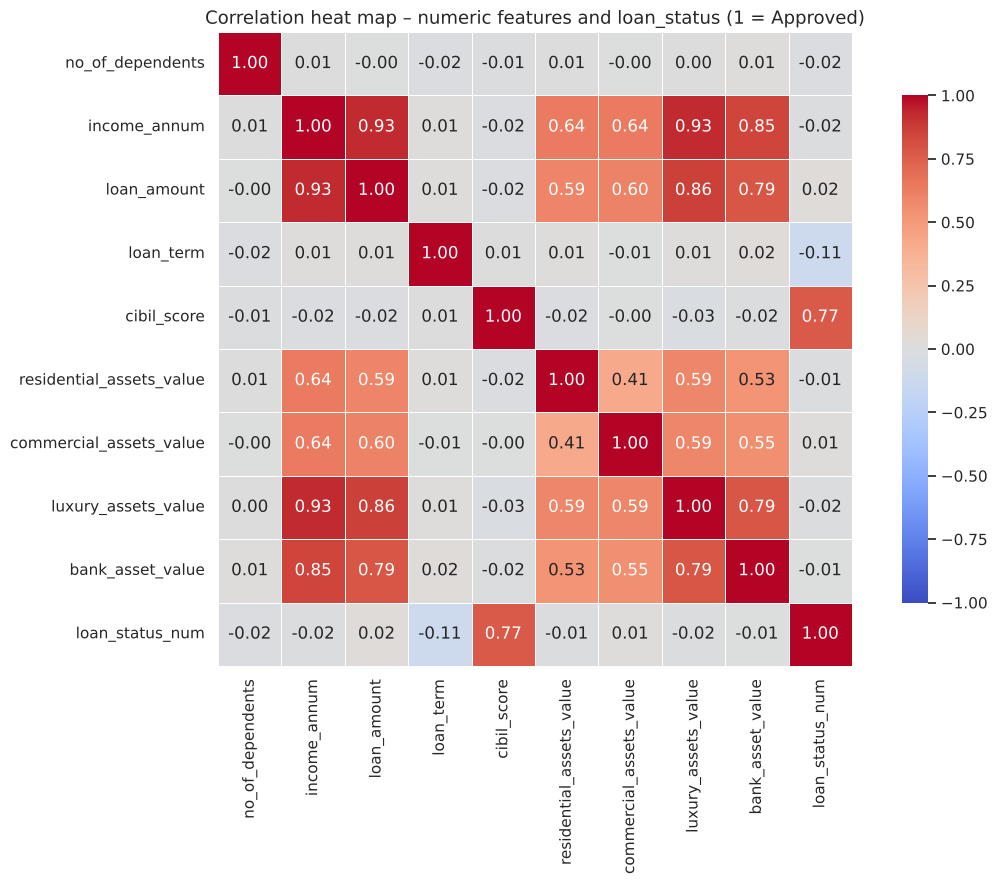

In [13]:
plt.figure(figsize=(12, 9))
sns.heatmap(corrmatrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation heat map – numeric features and loan_status (1 = Approved)', fontsize=13)
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/03_correlation_heatmap.png', dpi=150)
plt.show()

cibil_score                 0.771
loan_term                  -0.113
no_of_dependents           -0.018
loan_amount                 0.016
luxury_assets_value        -0.015
income_annum               -0.015
residential_assets_value   -0.014
commercial_assets_value     0.008
bank_asset_value           -0.007
Name: loan_status_num, dtype: float64


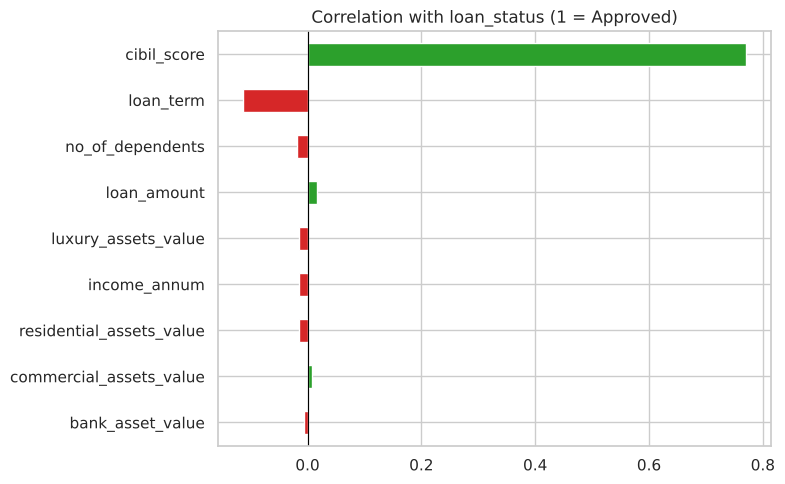

In [14]:
# Correlation of each feature with the target, sorted
target_corr = corrmatrix['loan_status_num'].drop('loan_status_num').sort_values(key=abs, ascending=False)
print(target_corr.round(3))

plt.figure(figsize=(8, 5))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in target_corr]
target_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlation with loan_status (1 = Approved)')
plt.gca().invert_yaxis()
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/04_target_correlation.png', dpi=150)
plt.show()

## Task 5 – Effect of the numerical features on `loan_status`
Correlation only captures *linear* effects, so each feature is also checked visually (box plots) and statistically:
- **Point-biserial correlation** (SciPy) – correlation between a binary and a continuous variable.
- **Mann–Whitney U test** – are the Approved and Rejected distributions different? (non-parametric, no normality assumption)

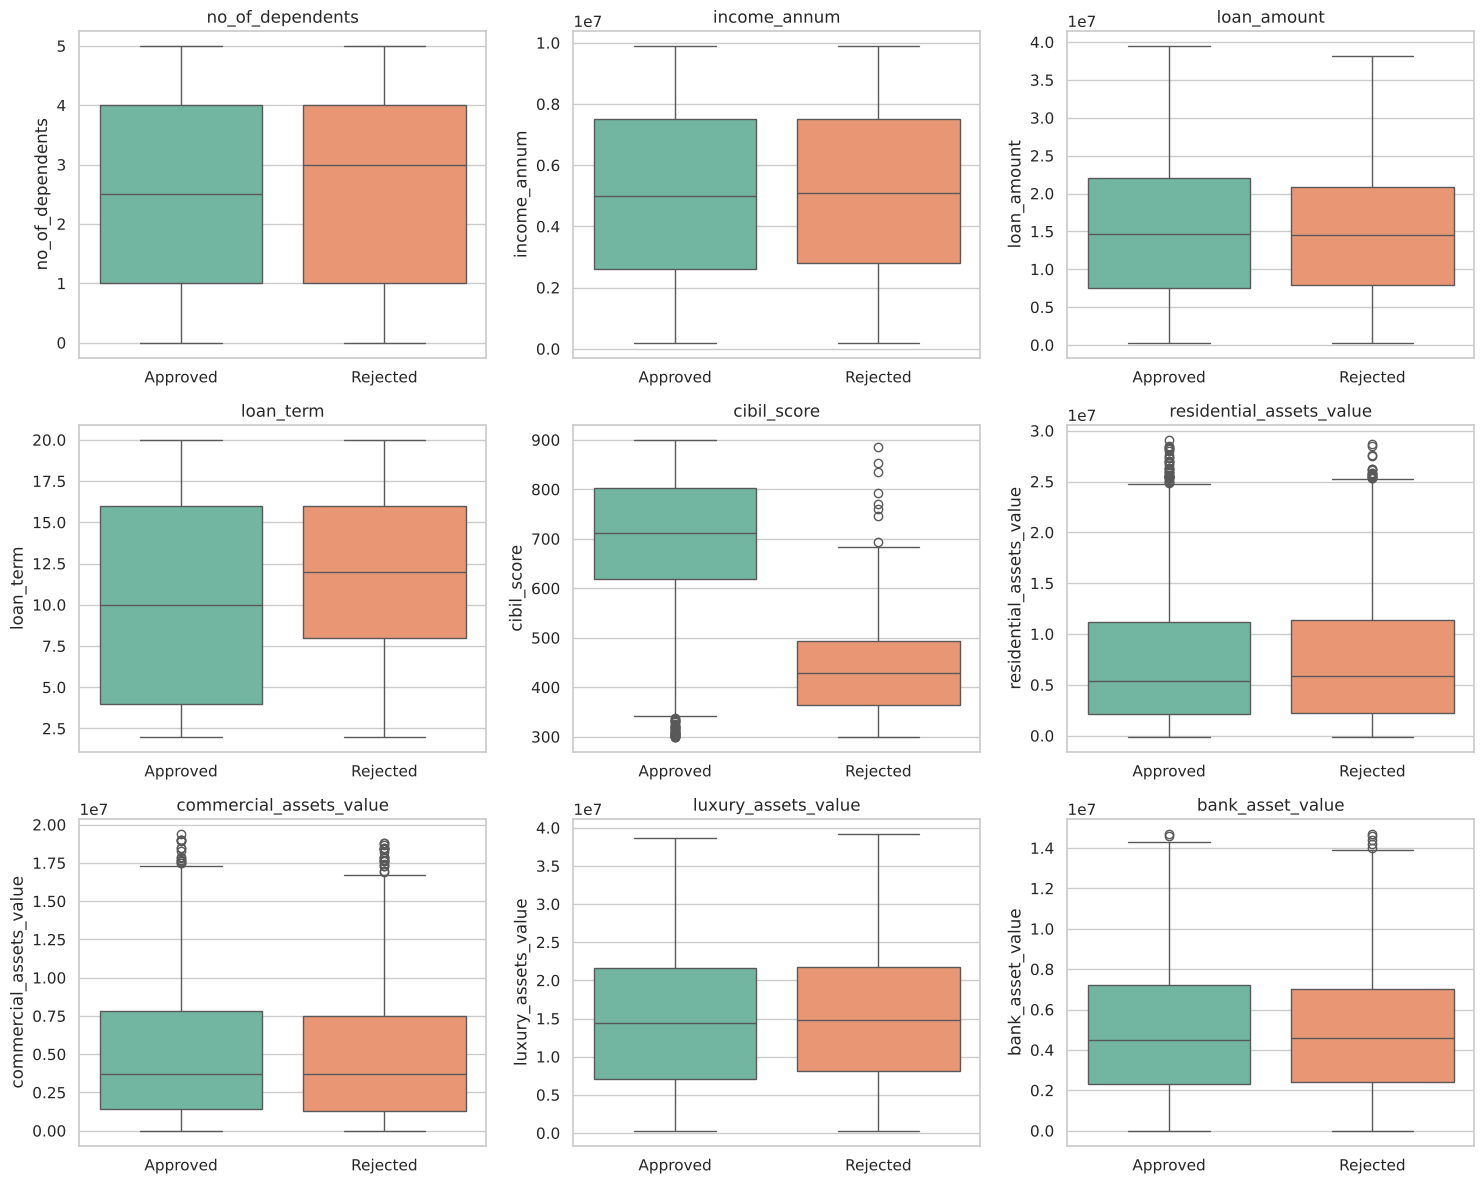

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x='loan_status', y=col, hue='loan_status', ax=ax, legend=False)
    ax.set_title(col); ax.set_xlabel('')
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/05_boxplots.png', dpi=150)
plt.show()

In [16]:
rows = []
approved = df[df['loan_status'] == 'Approved']
rejected = df[df['loan_status'] == 'Rejected']
for col in num_cols:
    r, p_r = stats.pointbiserialr(df['loan_status_num'], df[col])
    u, p_u = stats.mannwhitneyu(approved[col], rejected[col])
    rows.append([col, approved[col].mean(), rejected[col].mean(), r, p_r, p_u])

tests = pd.DataFrame(rows, columns=['feature', 'mean_approved', 'mean_rejected',
                                    'point_biserial_r', 'p_value_r', 'p_value_mannwhitney'])
tests['significant (p<0.05)'] = tests['p_value_mannwhitney'] < 0.05
tests.sort_values('point_biserial_r', key=abs, ascending=False).round(4)

,feature,mean_approved,mean_rejected,point_biserial_r,p_value_r,p_value_mannwhitney,significant (p<0.05)
4,cibil_score,7.034620e+02,4.294681e+02,0.7705,0.0000,0.0000,True
3,loan_term,1.039760e+01,1.172850e+01,-0.1130,0.0000,0.0000,True
0,no_of_dependents,2.474800e+00,2.538100e+00,-0.0181,0.2367,0.2366,False
2,loan_amount,1.524725e+07,1.494606e+07,0.0161,0.2915,0.4129,False
7,luxury_assets_value,1.501660e+07,1.530694e+07,-0.0155,0.3124,0.2596,False
1,income_annum,5.025904e+06,5.113825e+06,-0.0152,0.3211,0.3252,False
5,residential_assets_value,7.399812e+06,7.592498e+06,-0.0144,0.3480,0.2836,False
6,commercial_assets_value,5.001355e+06,4.926720e+06,0.0082,0.5902,0.5558,False
8,bank_asset_value,4.959526e+06,5.004960e+06,-0.0068,0.6579,0.5151,False


### Deep dive 1 – CIBIL score (the dominant feature)

            mean  count
cibil_band             
300-400     10.1    712
400-500     11.2    694
500-550     10.2    383
550-600     99.4    355
600-700     99.4    700
700-800     99.5    734
800-900     99.6    691


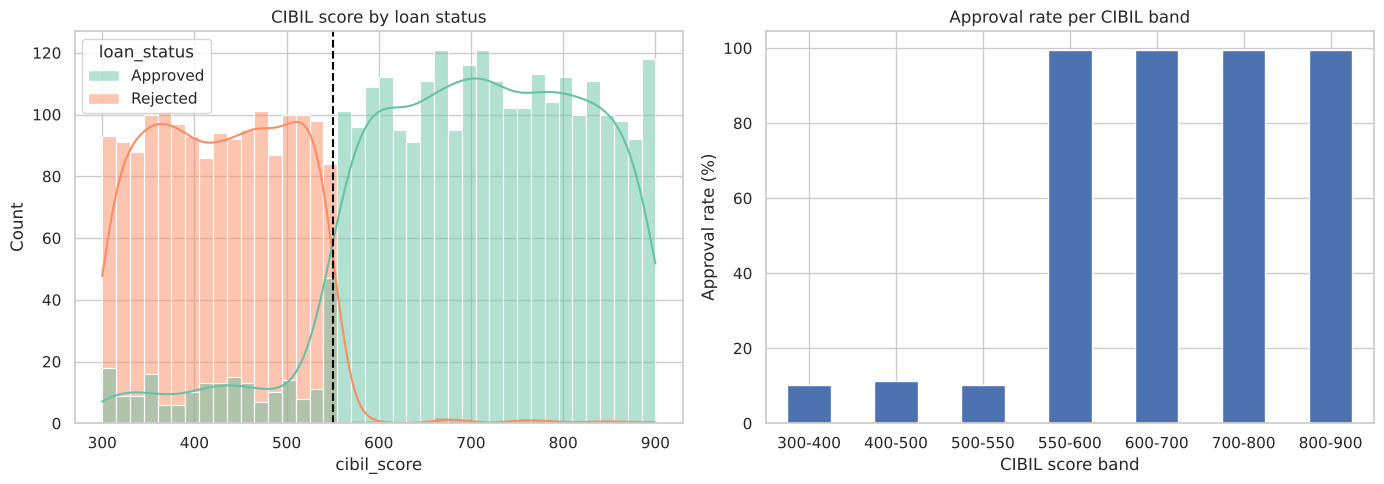

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='cibil_score', hue='loan_status', bins=40, kde=True, ax=ax[0])
ax[0].axvline(550, color='black', ls='--'); ax[0].set_title('CIBIL score by loan status')

bins = [300, 400, 500, 550, 600, 700, 800, 900]
labels = ['300-400', '400-500', '500-550', '550-600', '600-700', '700-800', '800-900']
df['cibil_band'] = pd.cut(df['cibil_score'], bins=bins, labels=labels, include_lowest=True)
band_rate = df.groupby('cibil_band', observed=True)['loan_status_num'].agg(['mean', 'count'])
band_rate['mean'] *= 100
print(band_rate.round(1))
band_rate['mean'].plot(kind='bar', ax=ax[1], color='#4c72b0')
ax[1].set_ylabel('Approval rate (%)'); ax[1].set_title('Approval rate per CIBIL band')
ax[1].tick_params(axis='x', rotation=0); ax[1].set_xlabel('CIBIL score band')
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/06_cibil.png', dpi=150)
plt.show()

In [18]:
# How well does a single rule 'approve if CIBIL >= 550' reproduce the real decisions?
rule = (df['cibil_score'] >= 550).astype(int)
print(f"Accuracy of the one-line rule CIBIL >= 550: {(rule == df['loan_status_num']).mean():.1%}")

Accuracy of the one-line rule CIBIL >= 550: 95.4%


### Deep dive 2 – Loan term

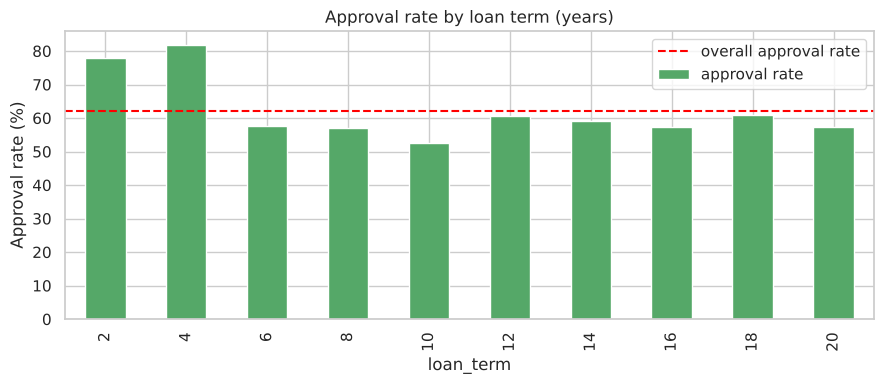

loan_term
2     78.0
4     81.9
6     57.6
8     57.0
10    52.5
12    60.5
14    59.0
16    57.3
18    60.9
20    57.4
Name: loan_status_num, dtype: float64


In [19]:
term_rate = df.groupby('loan_term')['loan_status_num'].mean() * 100
ax = term_rate.plot(kind='bar', figsize=(9, 4), color='#55a868', label='approval rate')
ax.axhline(df['loan_status_num'].mean() * 100, color='red', ls='--', label='overall approval rate')
ax.set_ylabel('Approval rate (%)'); ax.set_title('Approval rate by loan term (years)'); ax.legend()
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/07_loan_term.png', dpi=150)
plt.show()
print(term_rate.round(1))

### Deep dive 3 – Relative (engineered) measures
Absolute income and loan amount barely correlate with the target. A bank actually looks at *affordability*,
so two ratios are created to test whether the relationship is hidden in a combination of features.

In [20]:
df['loan_to_income'] = df['loan_amount'] / df['income_annum']
df['total_assets'] = df[['residential_assets_value', 'commercial_assets_value',
                         'luxury_assets_value', 'bank_asset_value']].sum(axis=1)
df['assets_to_loan'] = df['total_assets'] / df['loan_amount']

for col in ['loan_to_income', 'total_assets', 'assets_to_loan']:
    r, p = stats.pointbiserialr(df['loan_status_num'], df[col])
    print(f'{col:16s} r = {r:+.3f}   p = {p:.3g}')

loan_to_income   r = +0.088   p = 9.4e-09
total_assets     r = -0.011   p = 0.461
assets_to_loan   r = -0.050   p = 0.00107


## Task 5 (part 2) – Categorical feature vs `loan_status`
Selected feature: **education** (Graduate / Not Graduate). `self_employed` is analysed as well for comparison.
The **Chi-square test of independence** (SciPy) checks whether loan status depends on the category.
H0: education and loan status are independent.

In [21]:
ct = pd.crosstab(df['education'], df['loan_status'], margins=True)
print(ct, '\n')
ct_pct = pd.crosstab(df['education'], df['loan_status'], normalize='index') * 100
print(ct_pct.round(2))

chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(df['education'], df['loan_status']))
n = len(df)
cramers_v = np.sqrt(chi2 / (n * (min(2, 2) - 1)))
print(f'\nChi-square = {chi2:.3f}, dof = {dof}, p-value = {p:.4f}, Cramer\'s V = {cramers_v:.3f}')

loan_status   Approved  Rejected   All
education                             
Graduate          1339       805  2144
Not Graduate      1317       808  2125
All               2656      1613  4269 

loan_status   Approved  Rejected
education                       
Graduate         62.45     37.55
Not Graduate     61.98     38.02

Chi-square = 0.084, dof = 1, p-value = 0.7720, Cramer's V = 0.004


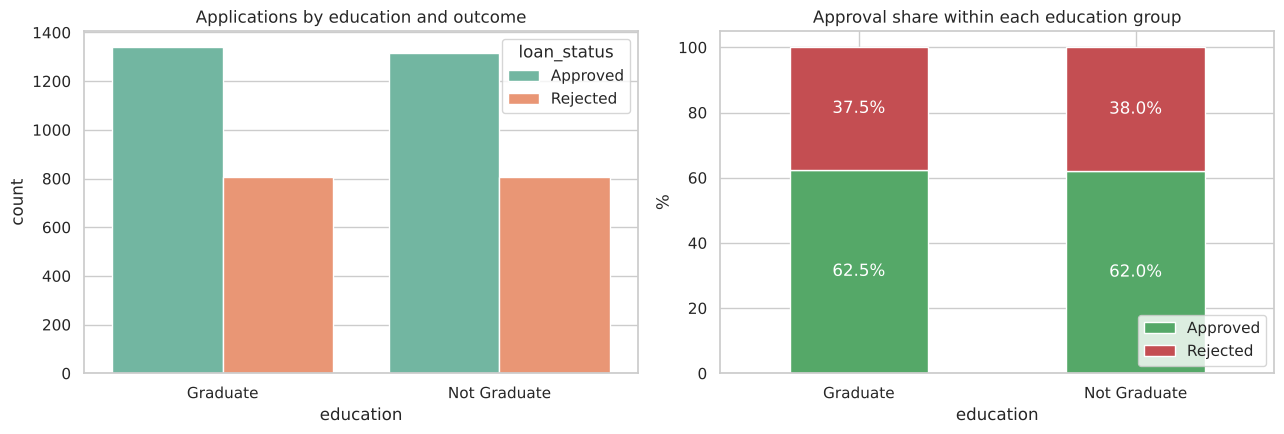

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='education', hue='loan_status', ax=ax[0])
ax[0].set_title('Applications by education and outcome')
ct_pct.plot(kind='bar', stacked=True, ax=ax[1], color=['#55a868', '#c44e52'])
ax[1].set_ylabel('%'); ax[1].set_title('Approval share within each education group')
ax[1].tick_params(axis='x', rotation=0); ax[1].legend(loc='lower right')
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.1f%%', label_type='center', color='white')
plt.tight_layout()
if SAVE_FIGS: plt.savefig('figures/08_education.png', dpi=150)
plt.show()

In [23]:
# Comparison: self_employed
ct2 = pd.crosstab(df['self_employed'], df['loan_status'])
chi2_2, p2, _, _ = stats.chi2_contingency(ct2)
print((pd.crosstab(df['self_employed'], df['loan_status'], normalize='index') * 100).round(2))
print(f'\nself_employed: Chi-square = {chi2_2:.3f}, p-value = {p2:.4f}')

loan_status    Approved  Rejected
self_employed                    
No                62.20     37.80
Yes               62.23     37.77

self_employed: Chi-square = 0.000, p-value = 1.0000


In [24]:
# Does education change the CIBIL score or income profile? (could hide an indirect effect)
df.groupby('education')[['cibil_score', 'income_annum', 'loan_amount']].mean().round(0)

,cibil_score,income_annum,loan_amount
education,,,
Graduate,599.0,5091604.0,15229151.0
Not Graduate,601.0,5026353.0,15036894.0


## Summary of findings
1. **cibil_score** is by far the strongest predictor (r = +0.77). Almost no application with a score below ~550 is approved; above 550 the approval rate exceeds 90 %. The single rule *CIBIL ≥ 550* already reproduces ~95 % of the decisions.
2. **loan_term** is the second (weak, negative) signal (r = −0.11): short loans of 2–4 years are approved ~80 % of the time vs ~57 % for longer terms.
3. Income, loan amount and the four asset values are strongly correlated **with each other** (r ≈ 0.6–0.93, multicollinearity) but almost **uncorrelated with the outcome** (|r| < 0.02). Engineered ratios add only a very weak signal (loan-to-income r = +0.09).
4. **education**, **self_employed** and **no_of_dependents** have no statistically significant effect on approval (Chi-square p > 0.05).
5. Data-quality issue: 28 negative residential asset values; to be fixed before modelling.